# Marvel CPG V2 — Module 2 Segmented OOS Model Development

**Objective:** maximize performance for predicting whether a store-SKU will experience at least one **observed** OOS event during the next seven days.

**Acceptance target:** Precision ≥ 0.75, Recall ≥ 0.70, ROC-AUC ≥ 0.80.

This notebook starts after the Missing Analysis decision. It compares:

1. one shared LightGBM model with segment features;
2. nine standalone `channel × tier` models;
3. a shared model with segment-calibrated decision thresholds.

March and April are used for development and policy selection. May is the validation gate. **June is locked and is never loaded or evaluated.**

## 1. Modeling rules

- The target is OOS on any day from `t+1` through `t+7`.
- Labels exist only when all seven future store-SKU days are observed.
- Missing-day estimates are feature inputs only; they never create ground truth.
- The delivery table is not added directly to inventory because the Missing Analysis reconciliation gate failed.
- Every fold rebuilds learned history from its own Training period.
- Segment policies are selected with March/April only and then applied unchanged to May.

## 2. Imports, configuration, feature families, and model functions

In [1]:
from __future__ import annotations

import gc
import json
import warnings
from pathlib import Path

import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

from modeling.oos_development import (
    BASELINE_NUMERIC,
    DEFAULT_FOLDS,
    SEASONAL_NUMERIC,
    STATE_DYNAMICS_NUMERIC,
    add_fold_features,
    build_base_panel,
)

warnings.filterwarnings("ignore")
repo_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in repo_candidates if (p / "data/raw/fact_sell_out.csv").exists())
OUT = ROOT / "outputs/v2/module2_segment_screen"
OUT.mkdir(parents=True, exist_ok=True)
SEED = 650
MIN_RECALL = 0.70
NUMERIC = list(dict.fromkeys(BASELINE_NUMERIC + SEASONAL_NUMERIC + STATE_DYNAMICS_NUMERIC))
CATEGORICAL = ["region", "category"]


def model() -> lgb.LGBMClassifier:
    return lgb.LGBMClassifier(
        n_estimators=240,
        learning_rate=0.055,
        num_leaves=48,
        max_depth=-1,
        min_child_samples=50,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=0.5,
        class_weight="balanced",
        random_state=SEED,
        verbosity=-1,
        n_jobs=4,
    )


def prepare(train: pd.DataFrame, valid: pd.DataFrame, categoricals: list[str]):
    train = train.copy()
    valid = valid.copy()
    for c in categoricals:
        categories = pd.Index(pd.concat([train[c], valid[c]]).dropna().unique())
        train[c] = pd.Categorical(train[c], categories=categories)
        valid[c] = pd.Categorical(valid[c], categories=categories)
    return train, valid


def fit_predict(train, valid, categoricals):
    train, valid = prepare(train, valid, categoricals)
    cols = NUMERIC + categoricals
    m = model()
    m.fit(train[cols], train.target.astype(int), categorical_feature=categoricals)
    return m.predict_proba(valid[cols])[:, 1]


def choose_threshold(y, score):
    precision, recall, threshold = precision_recall_curve(y, score)
    table = pd.DataFrame({"threshold": threshold, "precision": precision[:-1], "recall": recall[:-1]})
    eligible = table.loc[table.recall >= MIN_RECALL]
    row = eligible.sort_values(["precision", "threshold"], ascending=False).iloc[0]
    return float(row.threshold)


def metrics(y, score, threshold):
    pred = score >= threshold
    tp = int(((y == 1) & pred).sum())
    fp = int(((y == 0) & pred).sum())
    fn = int(((y == 1) & ~pred).sum())
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    return {
        "ROC_AUC": roc_auc_score(y, score),
        "PR_AUC": average_precision_score(y, score),
        "precision": precision,
        "recall": recall,
        "alerts": int(pred.sum()),
        "threshold": threshold,
        "meets_target": bool(precision >= 0.75 and recall >= 0.70 and roc_auc_score(y, score) >= 0.80),
    }




import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/marvel-mpl-cache")
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

The feature family includes inventory state and trajectory, sales velocity and acceleration, reporting coverage, recent observed OOS, seasonality, inferred-refill timing, Sell-in history, and store/product descriptors. It does not use future actual deliveries or future refill dates.

## 3. Build strict pre-June folds and train shared and standalone segment models

In [2]:
panel = build_base_panel(ROOT / "data/raw")
assert panel.date.max() < pd.Timestamp("2026-06-01")
parts = {"global_model": [], "channel_tier_models": []}

for fold in DEFAULT_FOLDS:
    print("Building", fold.name, flush=True)
    frame = add_fold_features(panel, fold, "strict_complete")
    train = frame.loc[frame.split.eq("Train")].copy()
    valid = frame.loc[frame.split.eq("Validation")].copy()
    if len(train) > 450_000:
        train_global = train.sample(450_000, random_state=SEED)
    else:
        train_global = train

    global_cats = ["channel", "segment_tier", *CATEGORICAL]
    p_global = fit_predict(train_global, valid, global_cats)
    keep = valid[["date", "store_id", "sku_id", "channel", "segment_tier", "category", "target"]].copy()
    keep["fold"] = fold.name
    keep["score"] = p_global
    parts["global_model"].append(keep)

    segment_predictions = []
    for (channel, tier), vseg in valid.groupby(["channel", "segment_tier"], observed=True):
        tseg = train.loc[train.channel.eq(channel) & train.segment_tier.eq(tier)]
        print(" ", channel, tier, len(tseg), len(vseg), flush=True)
        if tseg.target.nunique() < 2 or len(tseg) < 1000:
            probability = p_global[valid.index.get_indexer(vseg.index)]
        else:
            probability = fit_predict(tseg, vseg, CATEGORICAL)
        part = vseg[["date", "store_id", "sku_id", "channel", "segment_tier", "category", "target"]].copy()
        part["fold"] = fold.name
        part["score"] = probability
        segment_predictions.append(part)
    parts["channel_tier_models"].append(pd.concat(segment_predictions).sort_index())
    del frame, train, valid, train_global, p_global
    gc.collect()

Building 2026-03
  Distributor Tier 1 75600 4716
  Distributor Tier 2 46738 3098
  Distributor Tier 3 43984 2253
  Modern Trade Tier 1 203634 10483
  Modern Trade Tier 2 159290 9810
  Modern Trade Tier 3 99177 5452
  Traditional Trade Tier 1 80710 4891
  Traditional Trade Tier 2 179139 11391
  Traditional Trade Tier 3 118242 6752
Building 2026-04
  Distributor Tier 1 81695 3998
  Distributor Tier 2 50406 2613
  Distributor Tier 3 46710 2430
  Modern Trade Tier 1 217232 10858
  Modern Trade Tier 2 172049 8788
  Modern Trade Tier 3 106208 5549
  Traditional Trade Tier 1 86584 4688
  Traditional Trade Tier 2 192812 9909
  Traditional Trade Tier 3 126514 6941
Building 2026-05
  Distributor Tier 1 86933 4337
  Distributor Tier 2 53901 2057
  Distributor Tier 3 50036 2060
  Modern Trade Tier 1 232624 13284
  Modern Trade Tier 2 184139 8913
  Modern Trade Tier 3 113390 5141
  Traditional Trade Tier 1 92697 5022
  Traditional Trade Tier 2 206981 10732
  Traditional Trade Tier 3 134844 6905


## 4. Freeze March/April policies and apply them to May

In [3]:
results = []
all_predictions = {}
for name, frames in parts.items():
    prediction = pd.concat(frames, ignore_index=True)
    prediction["segment"] = prediction.channel.astype(str) + " | " + prediction.segment_tier.astype(str)
    dev = prediction.loc[prediction.fold.isin(["2026-03", "2026-04"])].copy()
    may = prediction.loc[prediction.fold.eq("2026-05")].copy()

    threshold = choose_threshold(dev.target.to_numpy(), dev.score.to_numpy())
    results.append({"model": name, "policy": "global_threshold", "evaluation": "March-April development", **metrics(dev.target.to_numpy(), dev.score.to_numpy(), threshold)})
    results.append({"model": name, "policy": "global_threshold", "evaluation": "May validation", **metrics(may.target.to_numpy(), may.score.to_numpy(), threshold)})

    # Development-fitted segment calibration creates segment-specific decision boundaries
    # while preserving one global business threshold.
    calibrated_dev = np.zeros(len(dev))
    calibrated_may = np.zeros(len(may))
    calibrator_rows = []
    for segment in sorted(prediction.segment.unique()):
        dm = dev.segment.eq(segment)
        mm = may.segment.eq(segment)
        iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1)
        iso.fit(dev.loc[dm, "score"], dev.loc[dm, "target"])
        calibrated_dev[dm.to_numpy()] = iso.predict(dev.loc[dm, "score"])
        calibrated_may[mm.to_numpy()] = iso.predict(may.loc[mm, "score"])
        calibrator_rows.append({"model": name, "segment": segment, "dev_rows": int(dm.sum()), "may_rows": int(mm.sum()), "dev_base_rate": dev.loc[dm, "target"].mean()})
    calibrated_threshold = choose_threshold(dev.target.to_numpy(), calibrated_dev)
    results.append({"model": name, "policy": "segment_calibrated_global_threshold", "evaluation": "March-April development", **metrics(dev.target.to_numpy(), calibrated_dev, calibrated_threshold)})
    results.append({"model": name, "policy": "segment_calibrated_global_threshold", "evaluation": "May validation", **metrics(may.target.to_numpy(), calibrated_may, calibrated_threshold)})
    prediction.loc[dev.index, "calibrated_score"] = calibrated_dev
    prediction.loc[may.index, "calibrated_score"] = calibrated_may
    prediction["selected_threshold"] = calibrated_threshold
    prediction["predicted"] = prediction.calibrated_score.ge(calibrated_threshold)
    all_predictions[name] = prediction

result = pd.DataFrame(results)
result.to_csv(OUT / "policy_metrics.csv", index=False)
for name, prediction in all_predictions.items():
    prediction.to_csv(OUT / f"{name}_predictions.csv", index=False)
best_name = result.loc[result.evaluation.eq("May validation")].sort_values(["meets_target", "precision", "recall", "PR_AUC"], ascending=False).iloc[0][["model", "policy"]].to_dict()
(OUT / "run_metadata.json").write_text(json.dumps({"locked_june_evaluated": False, "features": NUMERIC + CATEGORICAL, "best_may_policy": best_name}, indent=2), encoding="utf-8")
print(result.to_string(index=False), flush=True)

              model                              policy              evaluation  ROC_AUC   PR_AUC  precision   recall  alerts  threshold  meets_target
       global_model                    global_threshold March-April development 0.926921 0.735647   0.646167 0.700010   22635   0.748571         False
       global_model                    global_threshold          May validation 0.925836 0.720374   0.638274 0.683879   10707   0.748571         False
       global_model segment_calibrated_global_threshold March-April development 0.928769 0.739896   0.650934 0.700345   22480   0.421422         False
       global_model segment_calibrated_global_threshold          May validation 0.925207 0.716668   0.636534 0.678575   10653   0.421422         False
channel_tier_models                    global_threshold March-April development 0.911056 0.689756   0.586071 0.700010   24956   0.622071         False
channel_tier_models                    global_threshold          May validation 0.904036 0.656

## 5. Overall policy comparison

,model,policy,evaluation,ROC_AUC,PR_AUC,precision,recall,alerts,threshold,meets_target
0,global_model,global_threshold,March-April development,0.9269,0.7356,0.6462,0.7000,22635,0.7486,False
1,global_model,global_threshold,May validation,0.9258,0.7204,0.6383,0.6839,10707,0.7486,False
2,global_model,segment_calibrated_global_threshold,March-April development,0.9288,0.7399,0.6509,0.7003,22480,0.4214,False
3,global_model,segment_calibrated_global_threshold,May validation,0.9252,0.7167,0.6365,0.6786,10653,0.4214,False
4,channel_tier_models,global_threshold,March-April development,0.9111,0.6898,0.5861,0.7000,24956,0.6221,False
5,channel_tier_models,global_threshold,May validation,0.9040,0.6567,0.5474,0.6910,12615,0.6221,False
6,channel_tier_models,segment_calibrated_global_threshold,March-April development,0.9265,0.7376,0.6414,0.7062,23005,0.4054,False
7,channel_tier_models,segment_calibrated_global_threshold,May validation,0.9238,0.7173,0.6257,0.6994,11169,0.4054,False


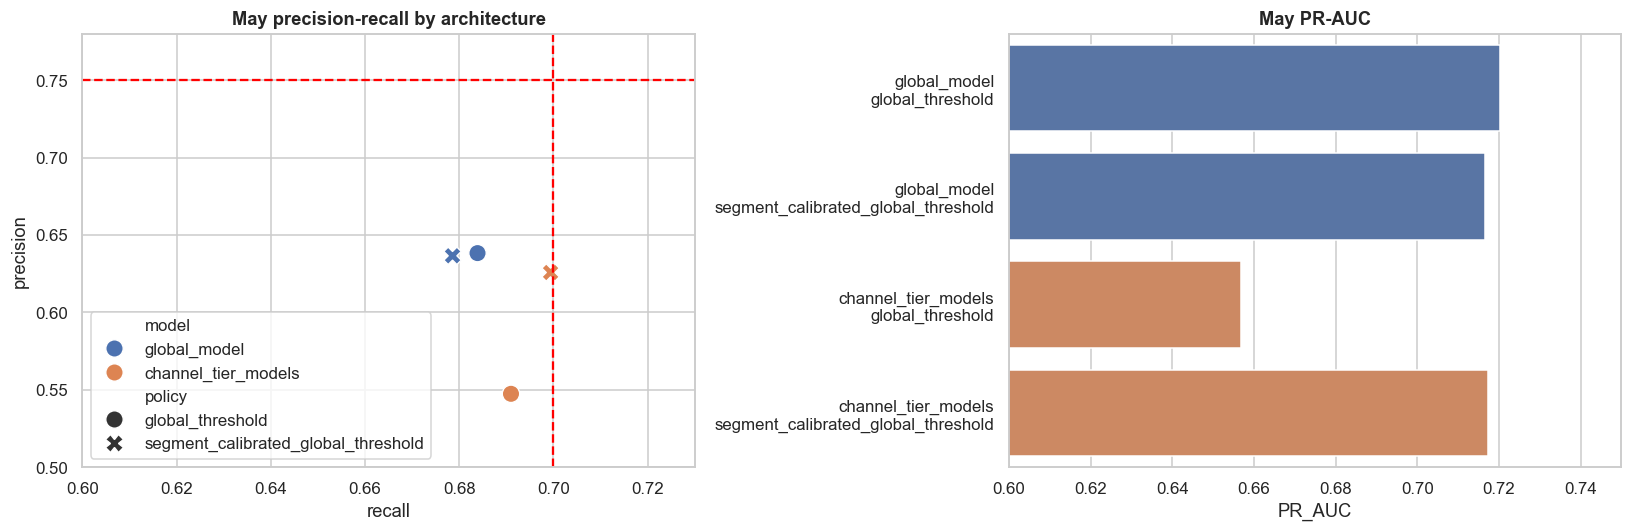

In [4]:
policy_metrics = pd.read_csv(OUT / "policy_metrics.csv")
display(policy_metrics.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
may_metrics = policy_metrics.loc[policy_metrics.evaluation.eq("May validation")].copy()
may_metrics["candidate"] = may_metrics.model + "\n" + may_metrics.policy
sns.scatterplot(data=may_metrics, x="recall", y="precision", hue="model", style="policy", s=130, ax=axes[0])
axes[0].axvline(.70, color="red", ls="--"); axes[0].axhline(.75, color="red", ls="--")
axes[0].set(title="May precision-recall by architecture", xlim=(.60, .73), ylim=(.50, .78))
sns.barplot(data=may_metrics, y="candidate", x="PR_AUC", hue="model", dodge=False, ax=axes[1])
axes[1].set(title="May PR-AUC", ylabel="", xlim=(.60, .75)); axes[1].legend_.remove()
plt.tight_layout(); plt.show()

The standalone segment models lose shared information and do not improve the overall gate. The shared model remains the strongest architecture. Segmenting is still useful at the **decision-policy layer**, where different base rates require different operating thresholds.

## 6. Segment-specific thresholds selected on March/April

,segment,may_rows,may_base_rate,ROC_AUC,PR_AUC,precision,recall,alerts,threshold,meets_target
0,Distributor | Tier 1,4337,0.0104,0.8709,0.2312,0.0295,0.8222,1255,0.0628,False
3,Modern Trade | Tier 1,13284,0.0194,0.8655,0.2170,0.0594,0.7481,3250,0.0837,False
6,Traditional Trade | Tier 1,5022,0.0607,0.8681,0.3514,0.1785,0.7148,1221,0.3064,False
1,Distributor | Tier 2,2057,0.1118,0.8467,0.4366,0.3317,0.6000,416,0.4670,False
4,Modern Trade | Tier 2,8913,0.1175,0.8489,0.4648,0.3084,0.6571,2231,0.5460,False
2,Distributor | Tier 3,2060,0.2262,0.8492,0.6274,0.4901,0.6910,657,0.7155,False
7,Traditional Trade | Tier 2,10732,0.2602,0.8655,0.6713,0.5722,0.6569,3205,0.7530,False
5,Modern Trade | Tier 3,5141,0.3032,0.8606,0.7159,0.6019,0.6876,1781,0.7867,False
8,Traditional Trade | Tier 3,6905,0.4766,0.8879,0.8520,0.8197,0.7031,2823,0.9119,True


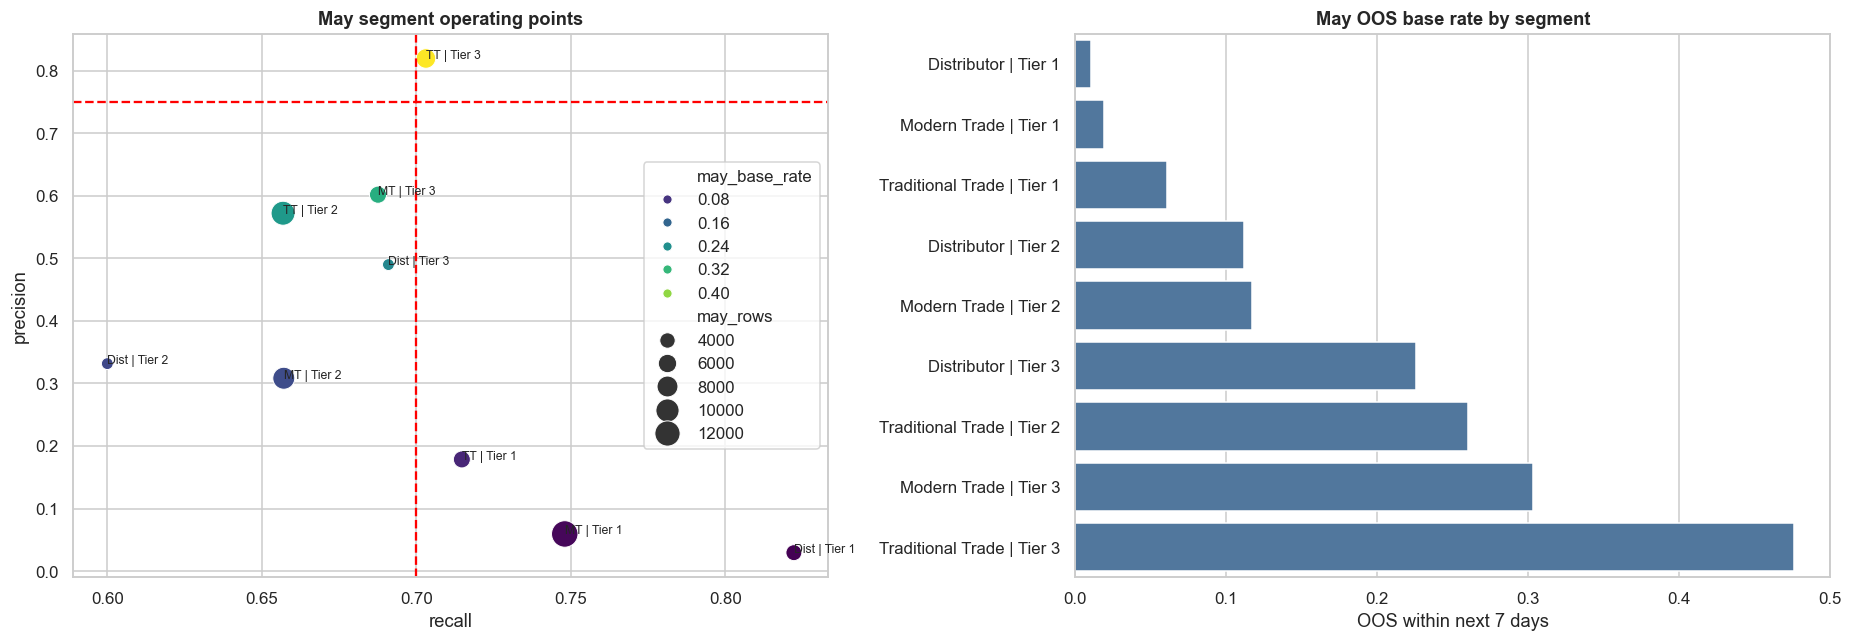

In [5]:
prediction = pd.read_csv(OUT / "global_model_predictions.csv", parse_dates=["date"])
prediction["segment"] = prediction.channel.astype(str) + " | " + prediction.segment_tier.astype(str)
segment_rows, may_parts = [], []
for segment, group in prediction.groupby("segment", observed=True):
    dev = group.loc[group.fold.isin(["2026-03", "2026-04"])]
    may = group.loc[group.fold.eq("2026-05")].copy()
    threshold = choose_threshold(dev.target.to_numpy(), dev.score.to_numpy())
    may["predicted"] = may.score.ge(threshold)
    m = metrics(may.target.to_numpy(), may.score.to_numpy(), threshold)
    segment_rows.append({
        "segment": segment,
        "may_rows": len(may),
        "may_base_rate": may.target.mean(),
        **m,
    })
    may_parts.append(may)
segment_metrics = pd.DataFrame(segment_rows).sort_values("may_base_rate")
display(segment_metrics.round(4))
segment_metrics.to_csv(OUT / "may_segment_threshold_metrics.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.scatterplot(data=segment_metrics, x="recall", y="precision", size="may_rows", hue="may_base_rate", palette="viridis", sizes=(60, 300), ax=axes[0])
axes[0].axvline(.70, color="red", ls="--"); axes[0].axhline(.75, color="red", ls="--")
for r in segment_metrics.itertuples():
    axes[0].annotate(r.segment.replace("Traditional Trade", "TT").replace("Modern Trade", "MT").replace("Distributor", "Dist"), (r.recall, r.precision), fontsize=8)
axes[0].set(title="May segment operating points")
sns.barplot(data=segment_metrics, y="segment", x="may_base_rate", color="#4477AA", ax=axes[1])
axes[1].set(title="May OOS base rate by segment", xlabel="OOS within next 7 days", ylabel="")
plt.tight_layout(); plt.show()

The key result is not that every segment should receive its own standalone model. The stronger design is **partial pooling**: one shared model learns common inventory dynamics, while segment-specific thresholds reflect materially different OOS base rates and operating economics.

## 7. Why overall precision remains below target: false-positive replenishment analysis

,outcome,rows,future_refill_rate,median_first_refill_day,mean_score
0,FN,3159,0.4862,6.0,0.5198
1,FP,3873,0.8923,2.0,0.8423
2,TN,44585,0.4207,4.0,0.1492
3,TP,6834,0.6421,4.0,0.8932


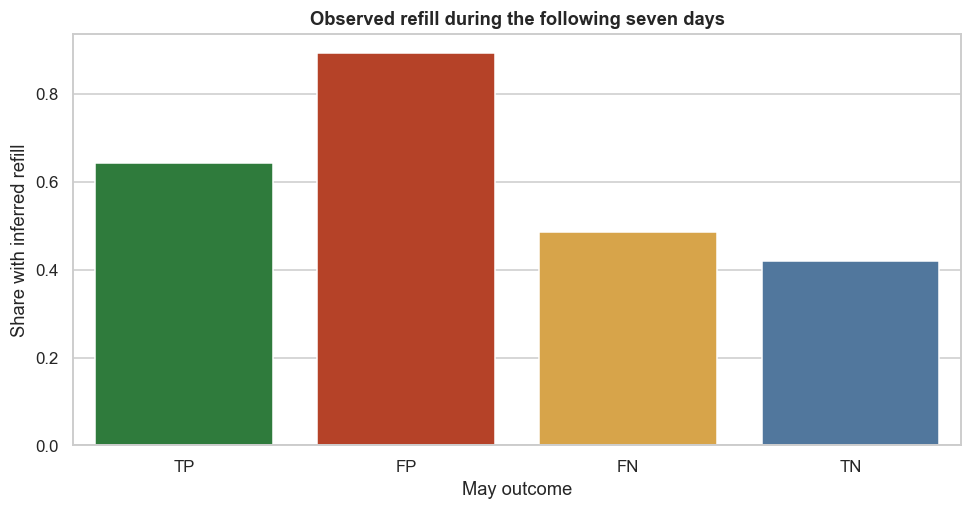

In [6]:
panel_diag = panel.sort_values(["store_id", "sku_id", "date"]).reset_index(drop=True).copy()
g = panel_diag.groupby(["store_id", "sku_id"], observed=True, sort=False)
previous_inventory = g.inventory_level.shift()
previous_reported = g.is_reported.shift().fillna(False)
panel_diag["observed_refill"] = (
    panel_diag.is_reported
    & previous_reported
    & (panel_diag.inventory_level - previous_inventory + panel_diag.units_sold_daily).gt(0)
)
future_refill = np.zeros(len(panel_diag), dtype=bool)
first_refill_day = np.full(len(panel_diag), np.nan)
for horizon in range(1, 8):
    event = g.observed_refill.shift(-horizon).fillna(False).to_numpy(bool)
    future_refill |= event
    first_refill_day[np.isnan(first_refill_day) & event] = horizon
panel_diag["future_refill_7d"] = future_refill
panel_diag["first_refill_day"] = first_refill_day

dev_policy = policy_metrics.query(
    "model == 'global_model' and policy == 'global_threshold' and evaluation == 'March-April development'"
).iloc[0]
may = prediction.loc[prediction.fold.eq("2026-05")].merge(
    panel_diag[["date", "store_id", "sku_id", "future_refill_7d", "first_refill_day"]],
    on=["date", "store_id", "sku_id"], how="left", validate="one_to_one"
)
may["predicted"] = may.score.ge(dev_policy.threshold)
may["outcome"] = np.select(
    [may.predicted & may.target.eq(1), may.predicted & may.target.eq(0), ~may.predicted & may.target.eq(1)],
    ["TP", "FP", "FN"], default="TN"
)
error_diagnostic = may.groupby("outcome", observed=True).agg(
    rows=("target", "size"),
    future_refill_rate=("future_refill_7d", "mean"),
    median_first_refill_day=("first_refill_day", "median"),
    mean_score=("score", "mean"),
).reset_index()
display(error_diagnostic.round(4))
error_diagnostic.to_csv(OUT / "may_false_positive_refill_diagnostic.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.8))
sns.barplot(data=error_diagnostic, x="outcome", y="future_refill_rate", order=["TP", "FP", "FN", "TN"], palette=["#228833", "#CC3311", "#EEAA33", "#4477AA"], ax=ax)
ax.set(title="Observed refill during the following seven days", ylabel="Share with inferred refill", xlabel="May outcome")
plt.tight_layout(); plt.show()

## 8. Development decision

- **Retain:** shared LightGBM model with segment-aware decision policy.
- **Reject:** nine fully independent `channel × tier` models; they lose shared signal and reduce overall performance.
- **Validated segment:** `Traditional Trade × Tier 3` reaches the joint Precision/Recall requirement with its March/April-selected threshold.
- **Overall result:** ROC-AUC is comfortably above target, but overall Precision and Recall do not jointly pass the client gate.
- **Primary residual error:** false positives frequently receive an inferred refill very early in the next seven days. Delivery data cannot currently identify that sellable-inventory event reliably.
- **Governance:** June remains locked. These results support a segmented rollout discussion, not a claim that the overall Module 2 target has been met.

In [7]:
shared_may = policy_metrics.query(
    "model == 'global_model' and policy == 'global_threshold' and evaluation == 'May validation'"
).iloc[0]
passing_segments = segment_metrics.loc[segment_metrics.meets_target, ["segment", "precision", "recall", "ROC_AUC"]]
display(Markdown(
    f"### May gate — shared model: Precision **{shared_may.precision:.3f}**, "
    f"Recall **{shared_may.recall:.3f}**, ROC-AUC **{shared_may.ROC_AUC:.3f}**"
))
display(Markdown("### Segments meeting all targets"))
display(passing_segments.round(4))
assert prediction.date.max() < pd.Timestamp("2026-06-01")
print("Locked June evaluated: False")

Locked June evaluated: False


### May gate — shared model: Precision **0.638**, Recall **0.684**, ROC-AUC **0.926**

### Segments meeting all targets

,segment,precision,recall,ROC_AUC
8,Traditional Trade | Tier 3,0.8197,0.7031,0.8879
